### Test for the new way of instantiate the Tan channel

In [1]:
# To get the parent path for the notebook
import sys
import os

parent_dir = os.path.abspath(os.path.join(os.getcwd(), '..'))

if parent_dir not in sys.path:
    sys.path.insert(0, parent_dir)

%matplotlib widget

import numpy as np
import matplotlib.pyplot as plt
from scipy.constants import c, pi

import plotly.io as pio
pio.renderers.default = 'notebook_connected' # 'browser' for avoid error but shown in the browser
import plotly.graph_objects as go

from utils.utils import *
from components.ris import RIS
from components.antenna import Antenna
from channels.tang_general_channel import tang_general_channel

In [2]:
# Create RIS
f = 28e9
lam = c/f

ris = RIS(center=[0,0,0],boresight='z',Ncol=32,Nrow=32,delta_h=lam/2,delta_v=lam/2,dx=0.47*lam,dy=0.47*lam,fc=f,radiation_factor=1,phase_shifts_dict={"0": 0,"1": pi},att_dict={"0": 1,"1": 1})

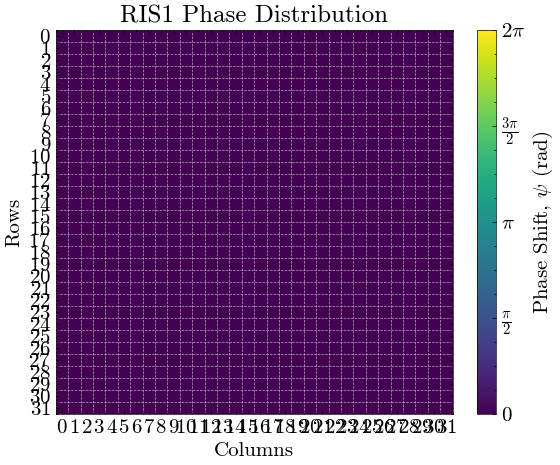

[9.81710781e-01 1.06616310e-06 8.30851244e-04]


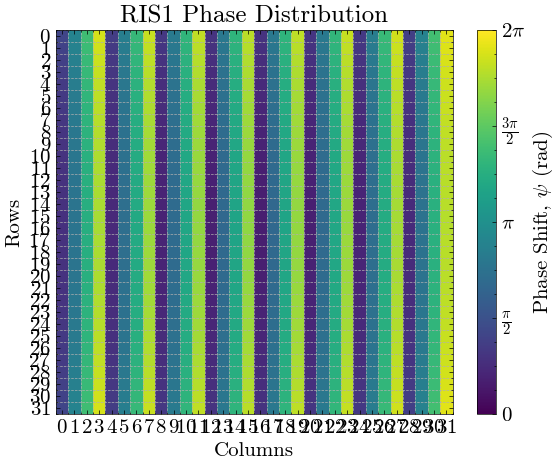

[2.38887271e-08 1.00000000e+00 6.64360048e-03]


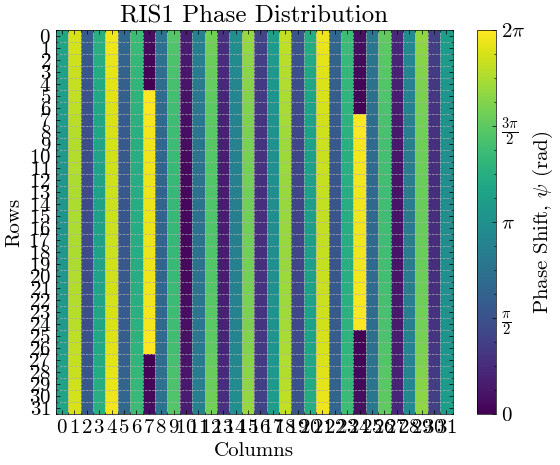

[8.43170766e-04 6.64360048e-03 1.00000000e+00]


In [8]:
max_bf = (ris.Nrow * ris.Ncol)**2

# Create antennas and channel
tx_pos = sph2cart([10,0,0])
tx_antenna = Antenna(tx_pos,0)

rx_pos1 = sph2cart([10,180,30])
rx_antenna1 = Antenna(rx_pos1,0)

rx_pos2 = sph2cart([10,180,45])
rx_antenna2 = Antenna(rx_pos2,0)

rx_pos = np.array([[0, 0, 20], rx_pos1[0], rx_pos2[0]])

channel = tang_general_channel()

# Generate rx locations as a 2D map
ris.reset_ris()
ris.plot_phase_dist()
print(channel.phase_bf_multrx(tx_antenna=tx_antenna, rx_positions=rx_pos, ris=ris) / max_bf)

channel.optimize(optimizer='direct_disc', mode='cont', tx_antenna=tx_antenna, rx_antenna=rx_antenna1, ris=ris)
ris.plot_phase_dist()
print(channel.phase_bf_multrx(tx_antenna=tx_antenna, rx_positions=rx_pos, ris=ris) / max_bf)

channel.optimize(optimizer='direct_disc', mode='cont', tx_antenna=tx_antenna, rx_antenna=rx_antenna2, ris=ris)
ris.plot_phase_dist()
print(channel.phase_bf_multrx(tx_antenna=tx_antenna, rx_positions=rx_pos, ris=ris) / max_bf)


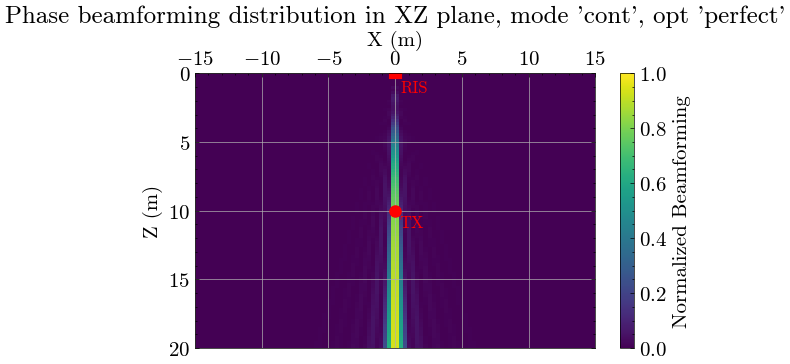

In [ ]:
xlim = [-15, 15]
zlim = [0, 20]
Nx = 100
Nz = 100

ris.reset_ris()
channel.plot_phase_bf_2d_map(tx_antenna=tx_antenna, ris=ris, ax1lim=xlim, ax2lim=zlim, Nax1=Nx, Nax2=Nz, plane='xz')

channel.optimize(optimizer='direct_disc', mode='cont', tx_antenna=tx_antenna, rx_antenna=rx_antenna1, ris=ris)
channel.plot_phase_bf_2d_map(tx_antenna=tx_antenna, ris=ris, ax1lim=xlim, ax2lim=zlim, Nax1=Nx, Nax2=Nz, plane='xz')

channel.optimize(optimizer='direct_disc', mode='cont', tx_antenna=tx_antenna, rx_antenna=rx_antenna2, ris=ris)
channel.plot_phase_bf_2d_map(tx_antenna=tx_antenna, ris=ris, ax1lim=xlim, ax2lim=zlim, Nax1=Nx, Nax2=Nz, plane='xz')


